Base torus: **L2 halo #29**, C = 3.060334, rho/2pi = 0.2932291, first converged in Week 8.

In [1]:
import sys, io, contextlib, time
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

import qpit
from cr3bp_3d import (MU_EARTH_MOON as MU, cr3bp_rhs_3d, halo_stability,
                      jacobi_constant_3d)

LU = 384400.0
INT = dict(method='DOP853', rtol=1e-12, atol=1e-12)
np.set_printoptions(precision=12)

The state below is the converged L2 halo #29 (family index 75 in the run that
produced it — the index is not portable, C and rho/2pi are what identify the
orbit). Regenerate it from `orbits.compute_halo_family` if you prefer; the
numbers must match to the digits shown.

In [2]:
s0 = np.array([1.043805201996, 0.0, -0.075586294085, 0.0, 0.392206924669, 0.0])
T0 = 3.131511429611
orbit = dict(state0=s0, period=T0)

N, eps = 31, 1e-4
U_seed, T_seed, rho_seed = qpit.seed_from_halo(orbit, MU, N, eps)
res = qpit.converge_torus(U_seed, T_seed, rho_seed, MU, tol=1e-12, itmax=15)

U0, T, rho = res['U0'], res['T'], res['rho']
print("\n%s in %d iterations" % (res['code'], res['n_iter']))
print("  C         = %.12f" % res['C'])
print("  rho/2pi   = %.9f" % (rho / (2*np.pi)))
print("  amplitude = %.4e  (%.2f km)" % (res['amplitude'], res['amplitude']*LU))
print("  tail      = %.3e   (fourier_tail now divides by the FUNDAMENTAL, not k=0)"
      % qpit.fourier_tail(U0))

  it 0: |F|inf=1.8445e-05  |dx|=3.140e-07  A=4.4655e-05  T=3.131511430  dC=+0.00e+00  rank=187
  it 1: |F|inf=7.4953e-10  |dx|=5.943e-09  A=4.4653e-05  T=3.131511400  dC=-4.00e-15  rank=187
  it 2: |F|inf=8.9815e-13  |dx|=5.539e-12  A=4.4653e-05  T=3.131511401  dC=+0.00e+00  rank=187

converged in 3 iterations
  C         = 3.060334462077
  rho/2pi   = 0.293229144
  amplitude = 4.4653e-05  (17.16 km)
  tail      = 2.810e-10   (fourier_tail now divides by the FUNDAMENTAL, not k=0)


## 2. Nullity of the invariance block
Structural claim: the solution set through a genuine torus is 4-dimensional in
`[U0, T, rho]` — two phase symmetries plus two physical parameters. For the
6N x (6N+2) invariance block that means

    nullity = 4    <=>    rank = 6N - 2    <=>    exactly 2 ZERO singular values

The 2 and the 4 are the same fact counted on different sides, and conflating
them is easy: a 186 x 188 matrix contributes 2 nullspace directions from its
shape alone before any singular value vanishes. `np.linalg.svd` returns only
`min(m, n) = 186` singular values but a 188 x 188 `Vt`, so the nullspace is
`Vt[-4:]`, not `Vt[-2:]`.

The test below is the one that matters: both symmetry tangents should lie in
that space to machine precision, and projecting them out should leave exactly
2 directions — the physical family.

In [3]:
JU, JT, Jr, F = qpit.invariance_jacobian(U0, T, rho, MU)
Jinv = np.hstack([JU, JT[:, None], Jr[:, None]])
Uu, sv, Vt = np.linalg.svd(Jinv)

print("Jinv %s, %d singular values, Vt %s" % (Jinv.shape, sv.size, Vt.shape))
print("  sigma[-3] = %.3e   sigma[-2] = %.3e   sigma[-1] = %.3e"
      % (sv[-3], sv[-2], sv[-1]))
print("  gap sigma[-3]/sigma[-2] = %.2e   -> exactly 2 zero singular values"
      % (sv[-3]/sv[-2]))

Nsp = Vt[-4:, :]                      # 2 from the shape + 2 from the zeros
lat = np.concatenate([qpit.flatten_curve(qpit.latitudinal_tangent(U0)), [0., 0.]])
lon = np.concatenate([qpit.flatten_curve(
        qpit.longitudinal_tangent(U0, T, rho, MU)), [0., 0.]])
for nm, v in (('latitudinal', lat), ('longitudinal', lon)):
    v = v / np.linalg.norm(v)
    print("  %-13s |Jinv @ v| = %.2e   overlap with 4-D nullspace = %.12f"
          % (nm, np.abs(Jinv @ v).max(), np.linalg.norm(Nsp @ v)))

B = np.linalg.qr(np.column_stack([lat/np.linalg.norm(lat),
                                  lon/np.linalg.norm(lon)]))[0]
resid = Nsp.T - B @ (B.T @ Nsp.T)
print("  after removing the symmetry span:",
      ["%.3f" % x for x in np.linalg.svd(resid, compute_uv=False)[:4]],
      "-> 2 physical directions remain")

Jinv (186, 188), 186 singular values, Vt (188, 188)
  sigma[-3] = 2.042e-04   sigma[-2] = 9.711e-13   sigma[-1] = 2.185e-13
  gap sigma[-3]/sigma[-2] = 2.10e+08   -> exactly 2 zero singular values
  latitudinal   |Jinv @ v| = 3.92e-07   overlap with 4-D nullspace = 1.000000000000
  longitudinal  |Jinv @ v| = 1.17e-11   overlap with 4-D nullspace = 1.000000000000
  after removing the symmetry span: ['1.000', '1.000', '0.000', '0.000'] -> 2 physical directions remain


**Reading of the result.** The two nulls sit at ~1e-12 and ~1e-13 against
sigma[-3] ~ 2e-4. The Week 8 `rcond` of 1e-8 relative to sigma_max ~ 2.2e3 puts
the cutoff at ~2e-5, which cleanly separates them. So the empirical rcond was
never compensating for a self-inflicted rank defect — the deficiency is
structural and exactly as predicted, and the 1e8 conditioning is the hyperbolic
multiplier of the underlying halo, which is a property of single shooting over a
full period and not something rcond can or should fix.

That is the open item from Week 8, settled. It also means the convergence log
can now separate the two sources honestly in the paper.

## 3. The family tangent

The tangent is the nullspace of the system **without** the arclength row:
(6N+3) x (6N+2), rank 6N+1, nullity exactly 1.

Take it from the *constrained* system, never from the invariance block. That
block has nullity 4 and two of those are the phase symmetries, so a tangent
drawn from it would be a mixture and the predictor would step along a
relabelling of the same curve — amplitude unchanged, residual small, a family
that goes nowhere while looking perfectly healthy.

In [4]:
for pin in ('rho', 'C'):
    t, d = qpit.torus_tangent(U0, T, rho, MU, pin=pin)
    print("pin=%-4s sv_null=%.2e  sv_next=%.2e  gap=%.2e  t_rho=%+.2e  dA/ds=%+.4f"
          % (pin, d['sv_null'], d['sv_next'], d['gap'], d['t_rho'], d['dA_ds']))

t, _ = qpit.torus_tangent(U0, T, rho, MU, pin='rho')
for nm, v in (('latitudinal', lat), ('longitudinal', lon)):
    print("  <t, %-13s> = %+.3e" % (nm, np.dot(t, v/np.linalg.norm(v))))

pin=rho  sv_null=9.66e-13  sv_next=1.69e-04  gap=1.75e+08  t_rho=+1.76e-17  dA/ds=+0.1134
pin=C    sv_null=9.35e-13  sv_next=1.15e-04  gap=1.23e+08  t_rho=-7.05e-04  dA/ds=+0.1134
  <t, latitudinal  > = -2.353e-17
  <t, longitudinal > = -1.280e-16


`t_rho` comes back at 1e-17 under `pin='rho'` because the pin row forces it,
and at ~7e-4 under `pin='C'` because rho is then free to drift — the two pins
really are different families, not two parameterisations of one.

The arclength row should lift the last null direction, taking the reported rank
from 6N+1 to 6N+2. That jump is the cheapest confirmation the row is doing its
job.

In [5]:
X = qpit.pack_X(U0, T, rho)
for lab, kw in (('without arclength', {}),
                ('with arclength   ', dict(tangent=t, X_prev=X, ds=1e-5))):
    J, rv, _ = qpit.assemble_system(U0, T, rho, MU, pin='rho',
                                    pin_target=rho, **kw)
    r = np.linalg.lstsq(J, -rv, rcond=qpit.RCOND_DEFAULT)[2]
    print("  %s : J %s  rank %d" % (lab, J.shape, r))
print("  (6N+1 = %d, 6N+2 = %d)" % (6*N+1, 6*N+2))

  without arclength : J (189, 188)  rank 187
  with arclength    : J (190, 188)  rank 188
  (6N+1 = 187, 6N+2 = 188)


## 4. Constant-rotation-number family

`pin='rho'` holds rho/2pi fixed and lets C float. Because omega_0 = 2pi/T and
omega_1 = rho/T, the frequency ratio is rho/2pi exactly, so this family never
moves in frequency and therefore never approaches a resonance.

**The pin target must come from a converged solve, never from `seed_rho`.**
Section 6B of `qpit.py` records what happens otherwise: rho0 is the linear
rotation number read off the monodromy at zero amplitude, the true torus sits
O(eps^2) away, and pinning the linear value while C is also pinned demands a
torus that does not exist. Pinning the *converged* rho with C free is a
different and entirely consistent request.

In [6]:
t0 = time.time()
famR = qpit.continue_torus_family(U0, T, rho, MU, pin='rho',
                                  n_steps=22, offgrid_every=6)
print("\n%d members, terminated=%s, %.0f s"
      % (len(famR['members']), famR['terminated'], time.time()-t0))

pin=rho at 1.842413048047   tangent gap 1.75e+08   dA/ds +1.134e-01
step   N     A [km]              C     rho/2pi     |F|inf      tail  its        ds
   0  31      17.16    3.060334462  0.29322914   6.64e-11   2.8e-10    0  0.00e+00
   1  31      18.25    3.060334461  0.29322914   7.34e-13   2.8e-10    2  2.49e-05
   2  31      19.87    3.060334460  0.29322914   8.44e-13   2.6e-10    2  3.73e-05
   3  31      22.31    3.060334458  0.29322914   8.26e-13   2.3e-10    2  5.59e-05
   4  31      25.97    3.060334455  0.29322914   2.05e-12   1.9e-10    2  8.39e-05
   5  31      31.46    3.060334449  0.29322914   8.29e-12   1.5e-10    2  1.26e-04
   6  31      39.69    3.060334438  0.29322914   1.24e-12   1.1e-10    3  1.89e-04
   7  31      52.04    3.060334417  0.29322914   5.54e-13   9.8e-11    3  2.83e-04
   8  31      70.56    3.060334374  0.29322914   7.78e-13   7.6e-11    3  4.25e-04
   9  31      98.34    3.060334286  0.29322914   8.41e-13   5.4e-11    3  6.37e-04
  10  31     140.01

## 5. Constant-energy family

`pin='C'` is the family the secondary research question needs, because it is the
one in which rho drifts — and the drift is the mechanism by which a family walks
into a resonance and terminates. Not needed for this week's gate; run it anyway,
it is cheap and it is half of the cross-check in section 6.

In [7]:
famC = qpit.continue_torus_family(U0, T, rho, MU, pin='C',
                                  n_steps=16, offgrid_every=0)
print("\n%d members, terminated=%s" % (len(famC['members']), famC['terminated']))

pin=C at 3.060334462077   tangent gap 1.23e+08   dA/ds +1.134e-01
step   N     A [km]              C     rho/2pi     |F|inf      tail  its        ds
   0  31      17.16    3.060334462  0.29322914   6.64e-11   2.8e-10    0  0.00e+00
   1  31      18.25    3.060334462  0.29322914   7.38e-13   2.7e-10    2  2.49e-05
   2  31      19.87    3.060334462  0.29322914   7.45e-13   2.5e-10    2  3.73e-05
   3  31      22.31    3.060334462  0.29322913   1.13e-12   2.3e-10    2  5.59e-05
   4  31      25.97    3.060334462  0.29322912   2.06e-12   2.1e-10    2  8.39e-05
   5  31      31.46    3.060334462  0.29322909   8.05e-12   1.6e-10    2  1.26e-04
   6  31      39.69    3.060334462  0.29322905   8.31e-13   1.2e-10    3  1.89e-04
   7  31      52.04    3.060334462  0.29322896   1.08e-12   9.7e-11    3  2.83e-04
   8  31      70.56    3.060334462  0.29322879   7.30e-13   6.9e-11    3  4.25e-04
   9  31      98.34    3.060334462  0.29322844   1.38e-12   5.2e-11    3  6.37e-04
  10  31     140.01  

## 6. Three-way cross-validation

Write the torus rotation number as a function of energy and amplitude:

    rho_torus(C, A) = rho_halo(C) + kappa * A^2 + O(A^4)

Then along a **constant-rho** family, 0 = rho_halo'(C) dC + 2 kappa A dA, and
with the measured C = C0 - c A^2 this gives dC/dA = -2cA, hence

    kappa = c * rho_halo'(C)

Three numbers from three independent computations:

  * `c`               from the constant-rho torus family (this notebook)
  * `rho_halo'(C)`    from the Phase 2 halo family (`orbits.compute_halo_family`)
  * `kappa`           from the constant-C torus family (this notebook)

If the continuation is right, they satisfy that one relation. Nothing in the
solver enforces it.

**A caution this check exposed.** Week 8 cell 17 swept eps and reported
`rho - rho0` growing as eps^2, which reads as kappa > 0. It is not kappa:
`converge_torus` takes `C_target` from each seed, and the seed's mean Jacobi
differs from the halo's by O(eps^2), so every row of that table sits at a
*different* energy and the column mixes the amplitude and energy effects. The
true fixed-energy coefficient is **negative**.

In [8]:
mR, mC = famR['members'], famC['members']
AR = np.array([m['amplitude'] for m in mR]); CR = np.array([m['C'] for m in mR])
AC = np.array([m['amplitude'] for m in mC])
RC = np.array([m['rho'] for m in mC]) / (2*np.pi)

c_fit = -np.polyfit(AR**2, CR, 1)[0]
k_fit = np.polyfit(AC**2, RC, 1)[0]

with contextlib.redirect_stdout(io.StringIO()):
    import orbits
hr = []
for sign in (+1, -1):
    with contextlib.redirect_stdout(io.StringIO()):
        fam = orbits.compute_halo_family([s0[0], s0[2], s0[4], T0/2],
                                         sign*2e-3, 4, MU, verbose=False)
    for o in fam:
        st = halo_stability(np.array(o['state0']), o['period'], MU)
        if st['theta'] is not None:
            hr.append((o['jacobi'], st['theta']/(2*np.pi)))
hr = np.array(sorted(set(hr)))
slope = np.polyfit(hr[:, 0], hr[:, 1], 1)[0]

print("  c      (constant-rho family)  = %+.6f" % c_fit)
print("  slope  (halo family, Phase 2) = %+.6f" % slope)
print("  c * slope                     = %+.6f" % (c_fit*slope))
print("  kappa  (constant-C family)    = %+.6f" % k_fit)
print("  relative disagreement         = %.2e" % abs(k_fit/(c_fit*slope) - 1))

  c      (constant-rho family)  = +2.783380
  slope  (halo family, Phase 2) = -3.981297
  c * slope                     = -11.081461
  kappa  (constant-C family)    = -11.080552
  relative disagreement         = 8.21e-05


**Forward pointer, not this week.** kappa < 0 means rho *decreases* with
amplitude at fixed energy, so the constant-C family walks down toward
2/7 = 0.285714, not up toward 3/10. From rho0/2pi = 0.2932291 that is a gap of
7.5e-3, reached near A ~ 1e4 km. So the resonance termination the secondary
question needs is reachable on this orbit — which is a Week 10 dataset-design
input, and something to settle before building anything on it.

## 7. Figures — the visual validation gate

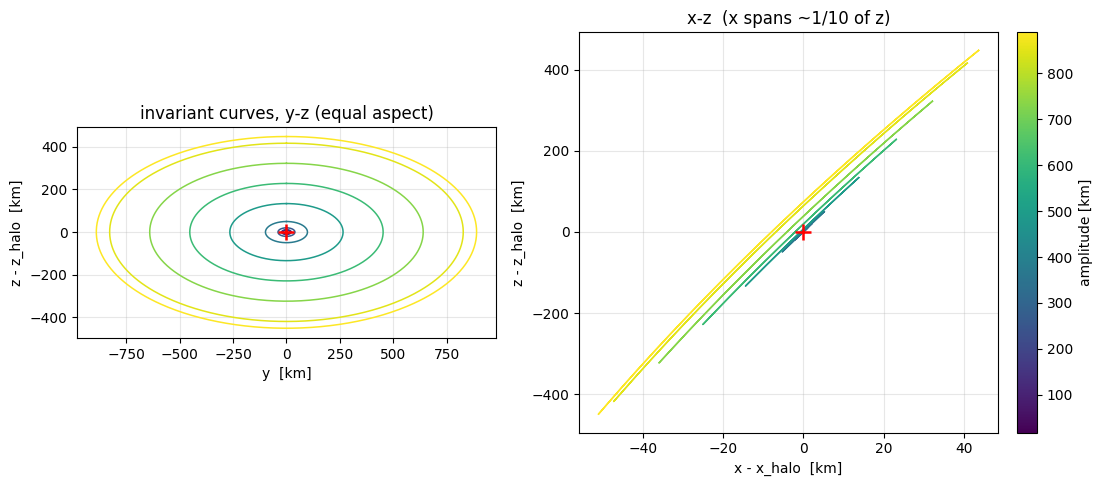

In [9]:
sel = list(range(0, len(mR), 3))
if sel[-1] != len(mR)-1: sel.append(len(mR)-1)
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.2))
th = np.linspace(0, 2*np.pi, 500)
for i in sel:
    F = qpit.evaluate_curve(mR[i]['U0'], th); col = cmap(i/(len(mR)-1))
    ax[0].plot(F[:, 1]*LU, (F[:, 2]-s0[2])*LU, color=col, lw=1.1)
    ax[1].plot((F[:, 0]-s0[0])*LU, (F[:, 2]-s0[2])*LU, color=col, lw=1.1)
ax[0].set_aspect('equal'); ax[0].set_xlabel('y  [km]')
ax[0].set_title('invariant curves, y-z (equal aspect)')
ax[1].set_xlabel('x - x_halo  [km]')
ax[1].set_title('x-z  (x spans ~1/10 of z)')
for a in ax:
    a.plot(0, 0, 'r+', ms=12, mew=1.8); a.set_ylabel('z - z_halo  [km]')
    a.grid(alpha=.3)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(AR[0]*LU, AR[-1]*LU))
fig.colorbar(sm, ax=ax, label='amplitude [km]', fraction=.03, pad=.02)
plt.show()

Nested closed curves around the fixed point, shrinking onto the halo as
A -> 0. That is the published picture (Baresi-Olikara-Scheeres 2018 Fig. 5;
McCarthy & Howell Fig. 4) and it is the gate.

Next: the torus itself. In the rotating frame an 890 km tube on a 38,000 km
orbit is invisible, so the honest picture is the co-moving one — subtract the
halo state at the same time and the 2-torus appears as a tube.

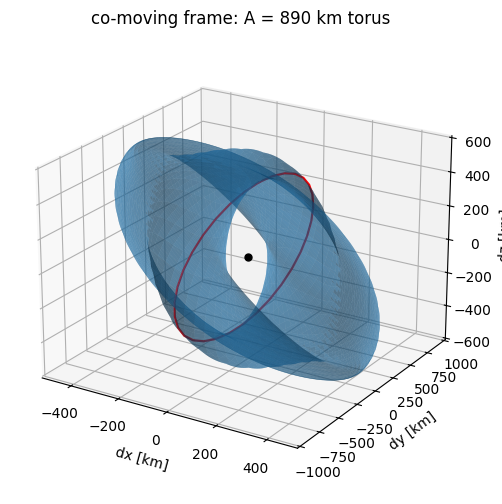

In [10]:
i = len(mR)-1
Ub, Tb = mR[i]['U0'], mR[i]['T']
ts = np.linspace(0, Tb, 240)
surf = np.array([solve_ivp(cr3bp_rhs_3d, [0, Tb], Ub[j], args=(MU,),
                           t_eval=ts, **INT).y.T for j in range(Ub.shape[0])])
ref = solve_ivp(cr3bp_rhs_3d, [0, Tb], s0, args=(MU,), t_eval=ts, **INT).y.T
dev = (surf[:, :, :3] - ref[None, :, :3]) * LU
dev = np.concatenate([dev, dev[:1]], axis=0)

fig = plt.figure(figsize=(7, 6))
a = fig.add_subplot(111, projection='3d')
a.plot_surface(dev[:, :, 0], dev[:, :, 1], dev[:, :, 2], alpha=.45,
               color='tab:blue', linewidth=0, rstride=1, cstride=3)
a.plot(dev[:, 0, 0], dev[:, 0, 1], dev[:, 0, 2], 'r-', lw=1.6)
a.scatter([0], [0], [0], color='k', s=25)
a.set_xlabel('dx [km]'); a.set_ylabel('dy [km]'); a.set_zlabel('dz [km]')
a.view_init(elev=22, azim=-58)
a.set_title('co-moving frame: A = %.0f km torus' % (AR[i]*LU))
plt.show()

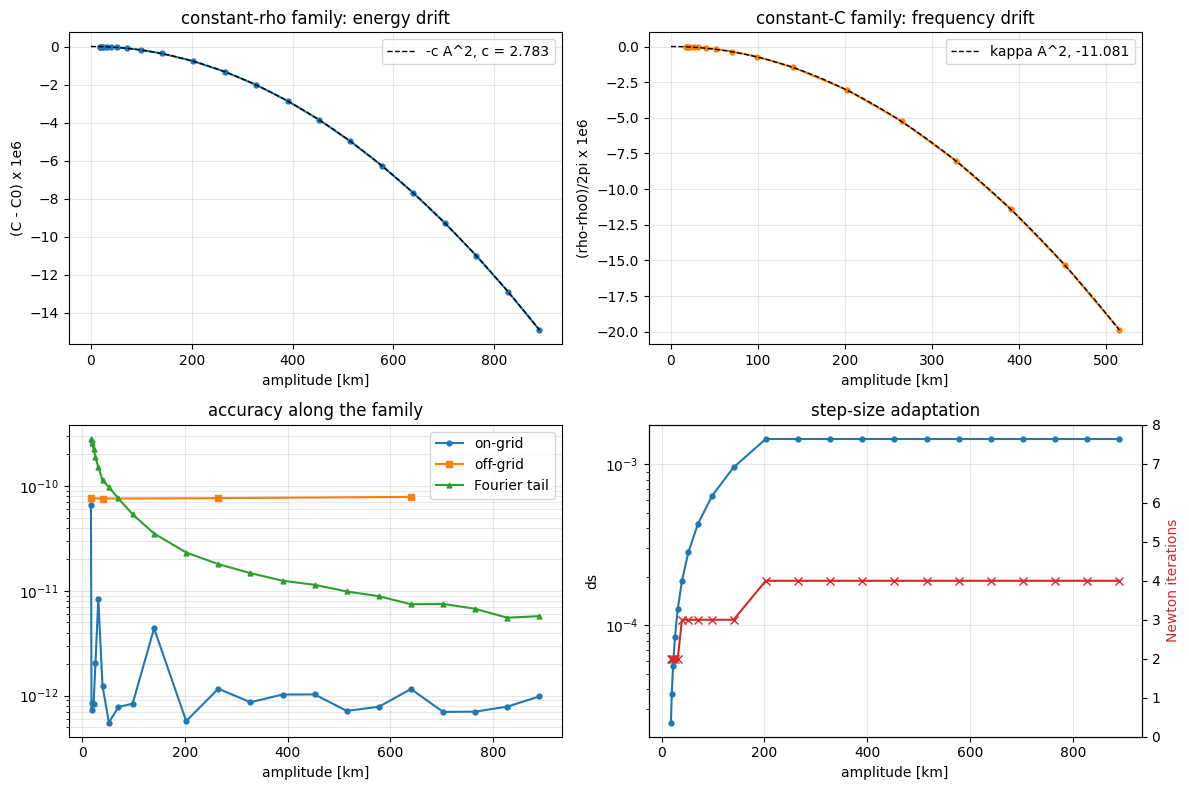

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
a = ax[0, 0]
a.plot(AR*LU, (CR-CR[0])*1e6, 'o-', ms=3.5)
Af = np.linspace(0, AR[-1], 200)
a.plot(Af*LU, -c_fit*Af**2*1e6, 'k--', lw=1, label='-c A^2, c = %.3f' % c_fit)
a.set_xlabel('amplitude [km]'); a.set_ylabel('(C - C0) x 1e6')
a.set_title('constant-rho family: energy drift'); a.legend(); a.grid(alpha=.3)

a = ax[0, 1]
a.plot(AC*LU, (RC-RC[0])*1e6, 'o-', ms=3.5, color='tab:orange')
Af = np.linspace(0, AC[-1], 200)
a.plot(Af*LU, k_fit*Af**2*1e6, 'k--', lw=1, label='kappa A^2, %.3f' % k_fit)
a.set_xlabel('amplitude [km]'); a.set_ylabel('(rho-rho0)/2pi x 1e6')
a.set_title('constant-C family: frequency drift'); a.legend(); a.grid(alpha=.3)

a = ax[1, 0]
a.semilogy(AR*LU, [m['res_inf'] for m in mR], 'o-', ms=3.5, label='on-grid')
og = np.array([m['offgrid'] for m in mR], float); k = np.isfinite(og)
a.semilogy(AR[k]*LU, og[k], 's-', ms=5, label='off-grid')
a.semilogy(AR*LU, [m['tail'] for m in mR], '^-', ms=3.5, label='Fourier tail')
a.set_xlabel('amplitude [km]'); a.set_title('accuracy along the family')
a.legend(); a.grid(alpha=.3, which='both')

a = ax[1, 1]
a.semilogy(AR[1:]*LU, [m['ds'] for m in mR[1:]], 'o-', ms=3.5)
a.set_xlabel('amplitude [km]'); a.set_ylabel('ds'); a.grid(alpha=.3)
a2 = a.twinx(); a2.plot(AR[1:]*LU, [m['n_iter'] for m in mR[1:]], 'x-',
                        color='tab:red', ms=6); a2.set_ylim(0, 8)
a2.set_ylabel('Newton iterations', color='tab:red')
a.set_title('step-size adaptation')
fig.tight_layout(); plt.show()

Two things to read off the accuracy panel.

The **Fourier tail falls** as amplitude grows. That is not the curve becoming
better resolved — it is the tail being noise-limited: the high modes sit on a
fixed ~1e-12 integrator floor while the fundamental grows with A, so the ratio
drops. Genuine spectral content will eventually overtake the floor and the tail
will turn upward; N = 31 is comfortable everywhere in this range and the
refinement branch never fired. **The turning point is the thing to watch when
this family is pushed further.**

The **off-grid residual sits ~1e-10, two orders above on-grid.** That gap is the
real accuracy of the torus, and it is the number to quote — not the on-grid
1e-12.

## 8. Stability and manifolds of one torus

`DG = (R(-rho) kron I) Phi_tilde` linearises the invariance condition. Read an
eigenvector as a curve of vectors and `DG w = lambda w` says

    Dphi_T( u(theta) ) w(theta) = lambda w(theta + rho)

— a *bundle* equation, not a per-node eigenproblem: the direction is transported
by the STM but lands one rotation further round the curve. Hence the spectrum
lies on circles, since `w -> e^{i k theta} w` sends `lambda -> lambda e^{-i k rho}`,
so every real bundle contributes N eigenvalues of equal modulus whose arguments
are spaced by rho. Both of those are checked below.

`torus_bundle` uses power iteration rather than `eig`, because the dominant
modulus is N-fold degenerate and numpy's eigenvectors carry an arbitrary
per-node phase that would have to be undone to rebuild a real bundle. Iterating
DG on a real curve stays real throughout and converges at R_u : 1 = 146 : 1.

In [12]:
tor = mR[len(mR)//2]
Ut, Tt, rt = tor['U0'], tor['T'], tor['rho']
DG = qpit.stability_matrix(Ut, Tt, rt, MU)
nu = qpit.stability_index(DG)
Vu, Ru = qpit.torus_bundle(Ut, Tt, rt, MU, 'unstable', DG=DG)
Vs, Rs = qpit.torus_bundle(Ut, Tt, rt, MU, 'stable', DG=DG)
ev = np.linalg.eigvals(DG)

print("  A = %.1f km" % (tor['amplitude']*LU))
print("  power-iteration R_u = %.6f   eig(DG) max modulus = %.6f"
      % (Ru, np.abs(ev).max()))
print("  R_u * R_s           = %.12f   (reciprocal bundles)" % (Ru*Rs))
print("  stability index nu  = %.6f" % nu)

Nn = Ut.shape[0]
for nm, rad in (('outer R_u', Ru), ('inner 1/R_u', 1/Ru)):
    circ = ev[np.abs(np.abs(ev)-rad) < 0.05*rad]; ang = np.angle(circ)
    ks = np.arange(-(Nn-1), Nn)
    err = max(np.abs((di - ks*rt + np.pi) % (2*np.pi) - np.pi).min()
              for di in ang[0]-ang)
    print("  %-12s %2d eigenvalues (N=%d)  max |arg - k*rho| = %.2e"
          % (nm, circ.size, Nn, err))

  A = 202.5 km
  power-iteration R_u = 146.318672   eig(DG) max modulus = 146.349275
  R_u * R_s           = 0.999212771790   (reciprocal bundles)
  stability index nu  = 73.178054
  outer R_u    31 eigenvalues (N=31)  max |arg - k*rho| = 5.76e-05
  inner 1/R_u  31 eigenvalues (N=31)  max |arg - k*rho| = 5.76e-05


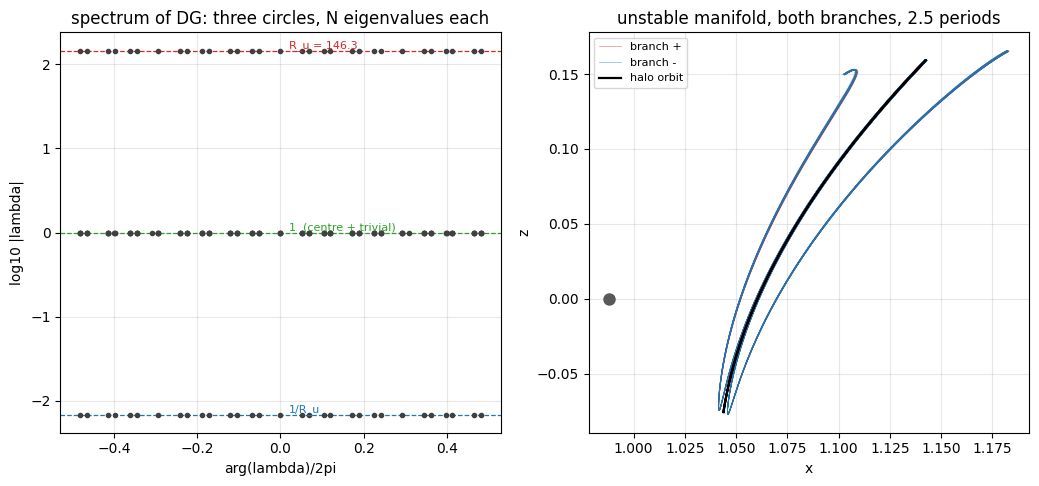

In [13]:
halo = solve_ivp(cr3bp_rhs_3d, [0, T0], s0, args=(MU,),
                 t_eval=np.linspace(0, T0, 700), **INT).y.T
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.2))
a = ax[0]
for lab, val, col in (('R_u = %.1f' % Ru, Ru, 'tab:red'),
                      ('1  (centre + trivial)', 1.0, 'tab:green'),
                      ('1/R_u', 1/Ru, 'tab:blue')):
    a.axhline(np.log10(val), ls='--', lw=.9, color=col)
    a.annotate(lab, (0.02, np.log10(val)), fontsize=8, color=col, va='bottom')
a.plot(np.angle(ev)/(2*np.pi), np.log10(np.abs(ev)), '.', ms=6, color='0.25')
a.set_xlabel('arg(lambda)/2pi'); a.set_ylabel('log10 |lambda|'); a.grid(alpha=.3)
a.set_title('spectrum of DG: three circles, N eigenvalues each')

a = ax[1]
for side, col, lab in ((+1, 'tab:red', 'branch +'), (-1, 'tab:blue', 'branch -')):
    for n, st in enumerate(qpit.torus_manifold(Ut, Tt, rt, MU, Vu, d=1e-6,
                                               n_periods=2.5, side=side)):
        a.plot(st[:, 0], st[:, 2], lw=.5, alpha=.55, color=col,
               label=lab if n == 0 else None)
a.plot(halo[:, 0], halo[:, 2], 'k-', lw=1.6, label='halo orbit')
a.plot(1-MU, 0, 'o', color='0.35', ms=8)
a.set_xlabel('x'); a.set_ylabel('z'); a.grid(alpha=.3); a.legend(fontsize=8)
a.set_title('unstable manifold, both branches, 2.5 periods')
plt.show()

**Before trusting the manifold picture**, halve `d` from 1e-6 to 5e-7 and
confirm the globalised surface is unchanged. If it moves, the displacement is
outside the linear regime of the bundle and the strands are not on the manifold.
Same check you ran on the Phase 2 tubes.

## 9. Save the family

The `.npz` is the Week 10 input: every member's curve, period, rotation number,
energy and amplitude. Nothing about labelling or sampling belongs here yet.

In [14]:
np.savez('../data/qpit_family_L2h29.npz',
         rho_U=np.array([m['U0'] for m in mR]),
         rho_T=np.array([m['T'] for m in mR]),
         rho_rho=np.array([m['rho'] for m in mR]),
         rho_C=CR, rho_A=AR,
         C_U=np.array([m['U0'] for m in mC]),
         C_T=np.array([m['T'] for m in mC]),
         C_rho=np.array([m['rho'] for m in mC]),
         C_C=np.array([m['C'] for m in mC]), C_A=AC,
         halo_state0=s0, halo_T=T0, mu=MU,
         c=c_fit, kappa=k_fit, drho_halo_dC=slope)
print('saved')

saved
